# 2D visibility: visibility polygons, isovist metrics and catchment

`get_visibility` computes the exact visibility polygon (isovist) of each observer within a view distance; obstacles
are walls of infinite height. This notebook shows

1. the visibility polygon of one observer and of several observers with individual radii;
2. isovist metrics (`isovist_metrics=True`) and an isovist field over an area (`get_isovist_grid`, `rasterize`);
3. the visibility catchment, how many observers see every cell (`get_visibility_catchment`).

2.5D viewsheds over building heights are covered in the [viewshed notebook](viewshed.ipynb).

The last section, *Your own area*, shows what to replace to get the same pictures for another territory.

In [1]:
# !pip install objectnat pyarrow matplotlib

In [2]:
import geopandas as gpd
import shapely
from shapely.geometry import Point

from objectnat import get_visibility, get_visibility_catchment

obstacles = gpd.read_parquet("examples_data/buildings.parquet")  # EPSG:32636, metres

In [3]:
import matplotlib.pyplot as plt
import numpy as np
from mpl_toolkits.axes_grid1.anchored_artists import AnchoredSizeBar


def map_extent(ax, bounds, bar=100, outline=True):
    """Show `bounds` (x0, y0, x1, y1 in metres) without coordinate axes, with a scale bar and the area outline."""
    x0, y0, x1, y1 = bounds
    pad = 0.012 * max(x1 - x0, y1 - y0)
    ax.set_xlim(x0 - pad, x1 + pad)
    ax.set_ylim(y0 - pad, y1 + pad)
    ax.set_aspect("equal")
    ax.set_axis_off()
    if outline:
        ax.plot([x0, x1, x1, x0, x0], [y0, y0, y1, y1, y0], color="#3d3d3d", linewidth=1, zorder=8)
    scale = AnchoredSizeBar(ax.transData, bar, f"{bar:g} m", loc="lower right", pad=0.4, sep=4, size_vertical=bar / 40)
    scale.patch.set(facecolor="white", edgecolor="none", alpha=0.85)
    ax.add_artist(scale)
from matplotlib.patches import Patch

## 1. One observer

Observers may be in any CRS; the calculation runs in an estimated UTM zone and the result is returned in the CRS of
the observers.

visible area 39.0 ha of 201.1 ha


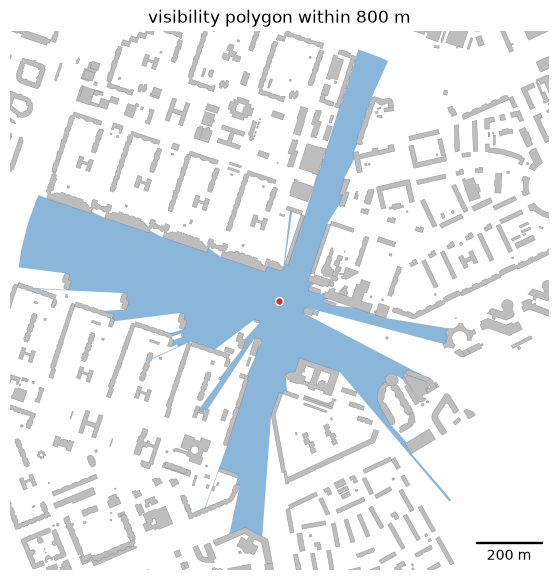

In [4]:
observer = gpd.GeoDataFrame(geometry=[Point(30.2312112, 59.9482336)], crs=4326)
visible = get_visibility(observer, obstacles, view_distance=800)
local = visible.to_crs(obstacles.crs)
print(f"visible area {local.area.iloc[0] / 1e4:.1f} ha of {3.14159 * 800 ** 2 / 1e4:.1f} ha")

c = observer.to_crs(obstacles.crs).geometry.iloc[0]
bounds = (c.x - 800, c.y - 800, c.x + 800, c.y + 800)
fig, ax = plt.subplots(figsize=(7, 7))
obstacles.plot(ax=ax, color="#bdbdbd", edgecolor="#8c8c8c", linewidth=0.3)
local.plot(ax=ax, color="#2b7bba", alpha=0.55, linewidth=0)
observer.to_crs(obstacles.crs).plot(ax=ax, color="#d7301f", markersize=30, edgecolor="white")
map_extent(ax, bounds, bar=200, outline=False)
ax.set_title("visibility polygon within 800 m")
plt.show()

## 2. Several observers

A `visibility_distance` column sets the radius of every observer (metres). Observers are processed in parallel by
the Rust extension; observers inside an obstacle get an empty polygon.

In [5]:
points = gpd.GeoDataFrame(
    {"visibility_distance": [300, 500, 800]},
    geometry=[Point(30.2312112, 59.9482336), Point(30.2390, 59.9465), Point(30.2250, 59.9500)],
    crs=4326,
)
many = get_visibility(points, obstacles)
many.to_crs(obstacles.crs).assign(area_ha=lambda g: g.area / 1e4)[["visibility_distance", "area_ha"]].round(2)

,visibility_distance,area_ha
0,300,15.54
1,500,21.70
2,800,1.87


## 3. Isovist metrics and isovist fields

`isovist_metrics=True` describes every visibility polygon with numbers; lengths are in metres and areas in m².
The [visibility page](../visibility.rst) explains each metric with examples. In short:

- `area` and `visible_share`: how much the observer sees, in m² and as a share of the view disc;
- `perimeter` and `compactness` (4πA/P²): the length of the boundary, and 1 for a full disc down to almost 0 for a
  spiky shape with long narrow views;
- `occlusivity` and `n_occlusions`: the total length and the number of edges where the view disappears behind a
  building corner, that is, how much space is hidden right behind corners;
- `min_radial`, `max_radial`, `mean_radial`, `std_radial` and `skew_radial`: statistics of the distance from the
  observer to the boundary of the view over all directions;
- `drift`: the distance from the observer to the centroid of the visible area, that is, how far the view is
  shifted to one side;
- `open_share`: the share of the boundary on the view limit, that is, not on walls.

`get_isovist_grid` maps the metrics over an area: it places an observer at the centre of every `cell_size` cell
of the open ground and returns the observers with their metrics. Buildings outside the area but within
`view_distance` still block the view. `rasterize` turns a metric into a `Raster`, which `plot` draws with
matplotlib; `to_geotiff` and `to_folium` write it to a file or a web map (see the
[insolation notebook](insolation.ipynb)).

In [6]:
import time

from objectnat import get_isovist_grid, rasterize

centre = (346050, 6647450)
square = shapely.box(centre[0] - 250, centre[1] - 250, centre[0] + 250, centre[1] + 250)
scene = obstacles[obstacles.intersects(square.buffer(200))]

start = time.perf_counter()
field = get_isovist_grid(obstacles, square, view_distance=200, cell_size=5)
print(f"{len(field)} observers in {time.perf_counter() - start:.1f} s")
field.drop(columns="geometry").describe().T[["mean", "min", "50%", "max"]].round(2)

7889 observers in 0.6 s


,mean,min,50%,max
area,26285.21,743.01,19527.09,70462.60
perimeter,1468.42,128.57,1490.88,2729.06
compactness,0.15,0.03,0.13,0.66
occlusivity,810.70,73.71,784.69,1823.30
n_occlusions,17.21,2.00,17.00,36.00
min_radial,14.74,0.00,11.42,78.83
max_radial,196.79,46.41,200.00,200.00
mean_radial,68.15,6.71,60.02,141.53
std_radial,51.42,12.46,50.24,92.14
skew_radial,1.16,-0.52,1.20,6.33


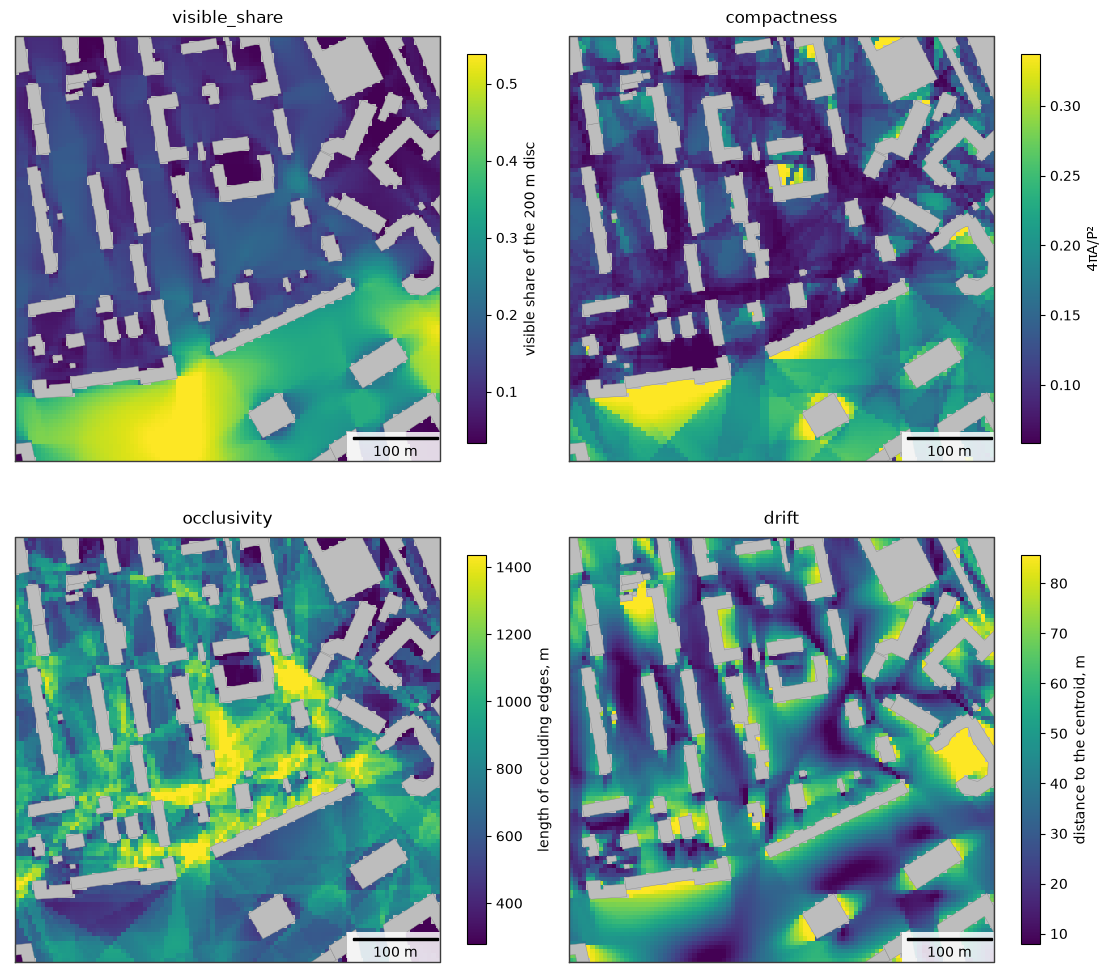

In [7]:
fig, axs = plt.subplots(2, 2, figsize=(11, 10), constrained_layout=True)
for ax, (col, label) in zip(axs.ravel(), [
    ("visible_share", "visible share of the 200 m disc"),
    ("compactness", "4πA/P²"),
    ("occlusivity", "length of occluding edges, m"),
    ("drift", "distance to the centroid, m"),
]):
    raster = rasterize(field, col)
    lo, hi = np.nanpercentile(raster.values, [2, 98])
    gpd.GeoSeries([square]).plot(ax=ax, color="#bdbdbd", zorder=0)  # cells without an observer lie under buildings
    im = raster.plot(ax=ax, cmap="viridis", vmin=lo, vmax=hi)
    scene.clip(square).plot(ax=ax, color="#bdbdbd", edgecolor="#8c8c8c", linewidth=0.3)
    map_extent(ax, square.bounds)
    ax.set_title(col)
    fig.colorbar(im, ax=ax, shrink=0.8, label=label)
plt.show()

Every cell shows what an observer standing at its centre sees. Open squares and wide streets have a high
`visible_share`, narrow yards a low one. `compactness` is high where the visible area is a simple, nearly convex
shape, in an open square or inside a closed courtyard, and low where long narrow views between buildings make it
spiky. `occlusivity` is high where many building corners hide space close to the observer, at crossings of
passages between buildings. `drift` is high next to walls that face an open area: the observer sees mostly to one
side.

## 4. Visibility catchment

`get_visibility_catchment` counts, for every `cell_size` cell, the observers whose visibility polygon contains the
cell centre, and returns the seen cells with their `count`; `rasterize` draws them. Observers along streets are usually placed with
`get_observer_points(urban_graph, spacing=15)`; for example, with a walk graph from IduEdu:

```python
import iduedu
from objectnat import get_observer_points

with iduedu.use_pbf(osm_id=1114252, region="northwestern-fed-district"):
    walk = iduedu.get_walk_graph(osm_id=1114252)
observers = get_observer_points(walk, spacing=15)
```

Here, to stay independent of downloads, observers are placed every 15 m on open ground within 12 m of a building,
over the area extended by the view distance (250 m): a cell near the edge of the area is also seen by observers
outside it, and without them its count would come out too low.

In [8]:
# observers over the area extended by the view distance; buildings far enough around them
near = obstacles[obstacles.intersects(square.buffer(500))]
footprints = shapely.union_all(near.geometry.values)
x0, y0, x1, y1 = square.buffer(250, join_style="mitre").bounds
xx, yy = np.meshgrid(np.arange(x0, x1, 15), np.arange(y0, y1, 15))
pts = shapely.points(xx.ravel(), yy.ravel())
pts = pts[~shapely.intersects(footprints.buffer(2), pts) & shapely.intersects(footprints.buffer(12), pts)]
street_observers = gpd.GeoDataFrame(geometry=pts, crs=obstacles.crs)

catchment = get_visibility_catchment(street_observers, near, view_distance=250, cell_size=4)
print(len(street_observers), "observers,", len(catchment), "cells seen")
catchment["count"].describe().round(1)

1547 observers, 83357 cells seen


count    83357.0
mean        25.0
std         18.8
min          1.0
25%          9.0
50%         21.0
75%         39.0
max         91.0
Name: count, dtype: float64

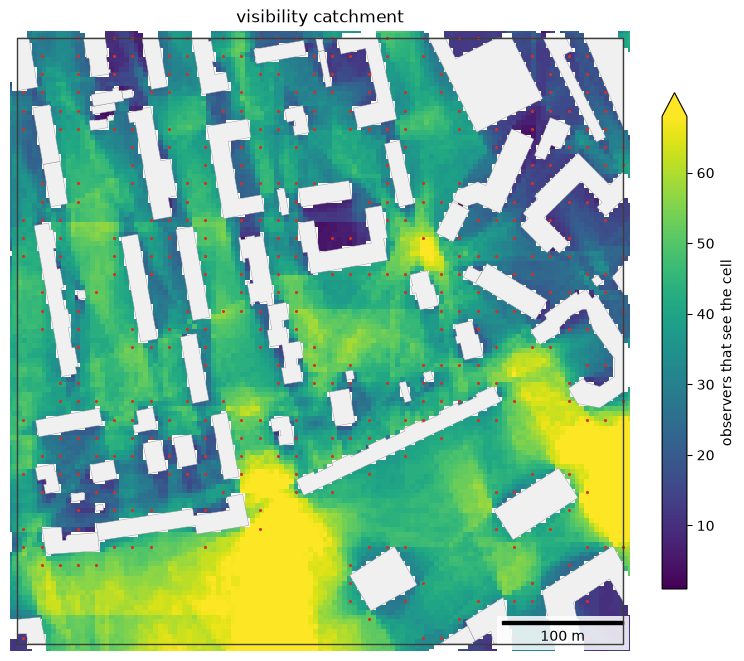

In [9]:
seen = rasterize(catchment, "count")
fig, ax = plt.subplots(figsize=(7.5, 6.5), constrained_layout=True)
im = seen.plot(ax=ax, cmap="viridis", vmin=1, vmax=np.nanpercentile(seen.values, 98))
scene.clip(square).plot(ax=ax, color="#f0f0f0", edgecolor="#8c8c8c", linewidth=0.3)
street_observers.plot(ax=ax, color="#d7301f", markersize=1.5)
map_extent(ax, square.bounds)
fig.colorbar(im, ax=ax, shrink=0.8, extend="max", label="observers that see the cell")
ax.set_title("visibility catchment")
plt.show()

The counts are in observers, so rasters of different areas or scenarios with the same observer spacing share one
colour scale. `weight_column` replaces counts by sums of observer weights, for example pedestrian flow.

### Isovist metrics of your own observers

`get_isovist_grid` places observers on a grid. For observers placed in another way, for example along the streets,
`get_visibility(observers, obstacles, view_distance, isovist_metrics=True)` returns the same metrics, one row per
observer; draw them as points. Unlike catchment counts, these values have no edge effect: each describes its own
observer.

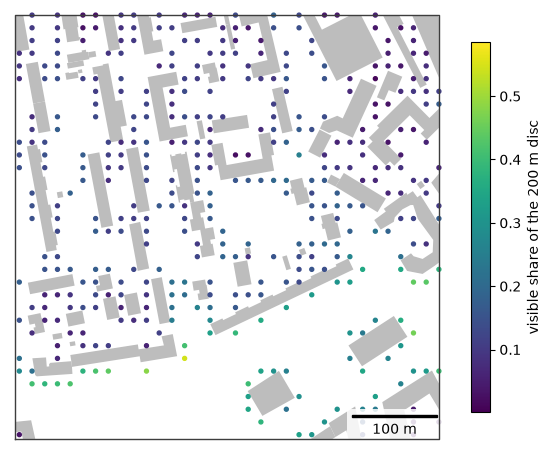

In [10]:
street_metrics = get_visibility(street_observers, obstacles, view_distance=200, isovist_metrics=True)
street_points = street_metrics.set_geometry(street_observers.geometry)

fig, ax = plt.subplots(figsize=(7, 6))
scene.clip(square).plot(ax=ax, color="#bdbdbd", linewidth=0)
street_points.plot(ax=ax, column="visible_share", cmap="viridis", markersize=8, legend=True,
                   legend_kwds={"label": "visible share of the 200 m disc", "shrink": 0.8})
map_extent(ax, square.bounds)
plt.show()

## 5. Your own area

Observers every 20 m along the pedestrian graph of the district from IduEdu (`get_observer_points`); the buildings
are only obstacles, they add no observers. Some 44 thousand observers take a few seconds. The raster covers
everything the observers see, also beyond the district boundary. Counts depend on the observer spacing, so compare
rasters made with the same spacing. `Raster.plot` draws the raster, `Raster.explore` shows it on a web map with a
colour bar and `Raster.to_geotiff` writes a GeoTIFF for GIS (requires `rasterio`).

The catchment and `visible_share` answer different questions. `visible_share` (an isovist metric, section 3) looks
out of a place: how much of its view disc an observer standing there sees. The catchment looks at a place from all
observers: how many of them see it, that is how visible it is from the streets. The middle of a large square has a
high `visible_share`, but a low catchment if few streets lead to it. The isovist field of section 3 is obtained for
any area in the same way, for example
`rasterize(get_isovist_grid(my_obstacles, my_area, view_distance=200, cell_size=5), "visible_share")`.

2026-11-06 20:43:45.799 | WARNING  | Removing 336 nodes outside the largest connected component. Retaining 19802 of 20138 nodes.


43799 observers, 782044 cells seen, 1.2 s


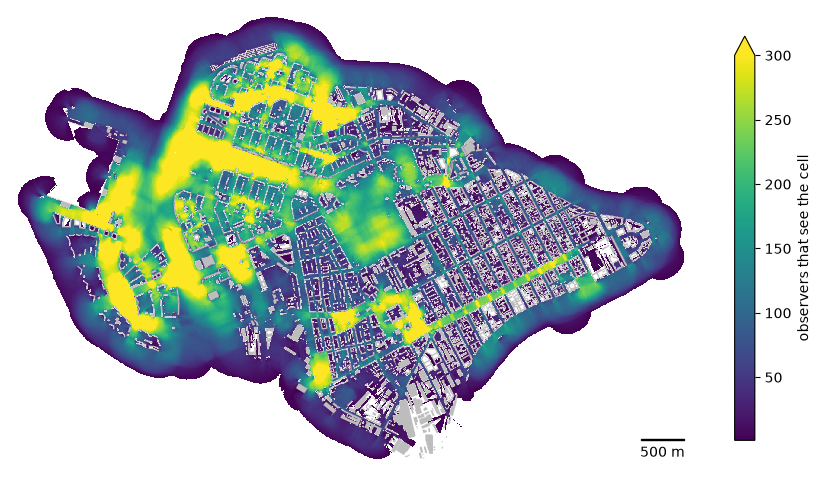

In [11]:
import iduedu

from objectnat import get_observer_points

OSM_ID, REGION = 1114252, "northwestern-fed-district"  # your territory
with iduedu.use_pbf(osm_id=OSM_ID, region=REGION):  # downloaded once, then cached
    my_boundary = iduedu.get_4326_boundary(osm_id=OSM_ID)
    my_walk = iduedu.get_walk_graph(territory=my_boundary, clip_by_territory=True)
my_observers = get_observer_points(my_walk, spacing=20)  # every 20 m along the pedestrian graph
my_obstacles = obstacles  # your building footprints, any CRS

start = time.perf_counter()
cells = get_visibility_catchment(my_observers, my_obstacles, view_distance=250, cell_size=5)
print(f"{len(my_observers)} observers, {len(cells)} cells seen, {time.perf_counter() - start:.1f} s")

seen = rasterize(cells, "count")
fig, ax = plt.subplots(figsize=(11, 7.5))
im = seen.plot(ax=ax, cmap="viridis", vmin=1, vmax=300)
my_obstacles.to_crs(seen.crs).plot(ax=ax, color="#bdbdbd", linewidth=0)
map_extent(ax, seen.bounds, bar=500, outline=False)
fig.colorbar(im, ax=ax, shrink=0.7, extend="max", label="observers that see the cell")
plt.show()
# seen.to_geotiff("my_visibility_count.tif")  # for GIS


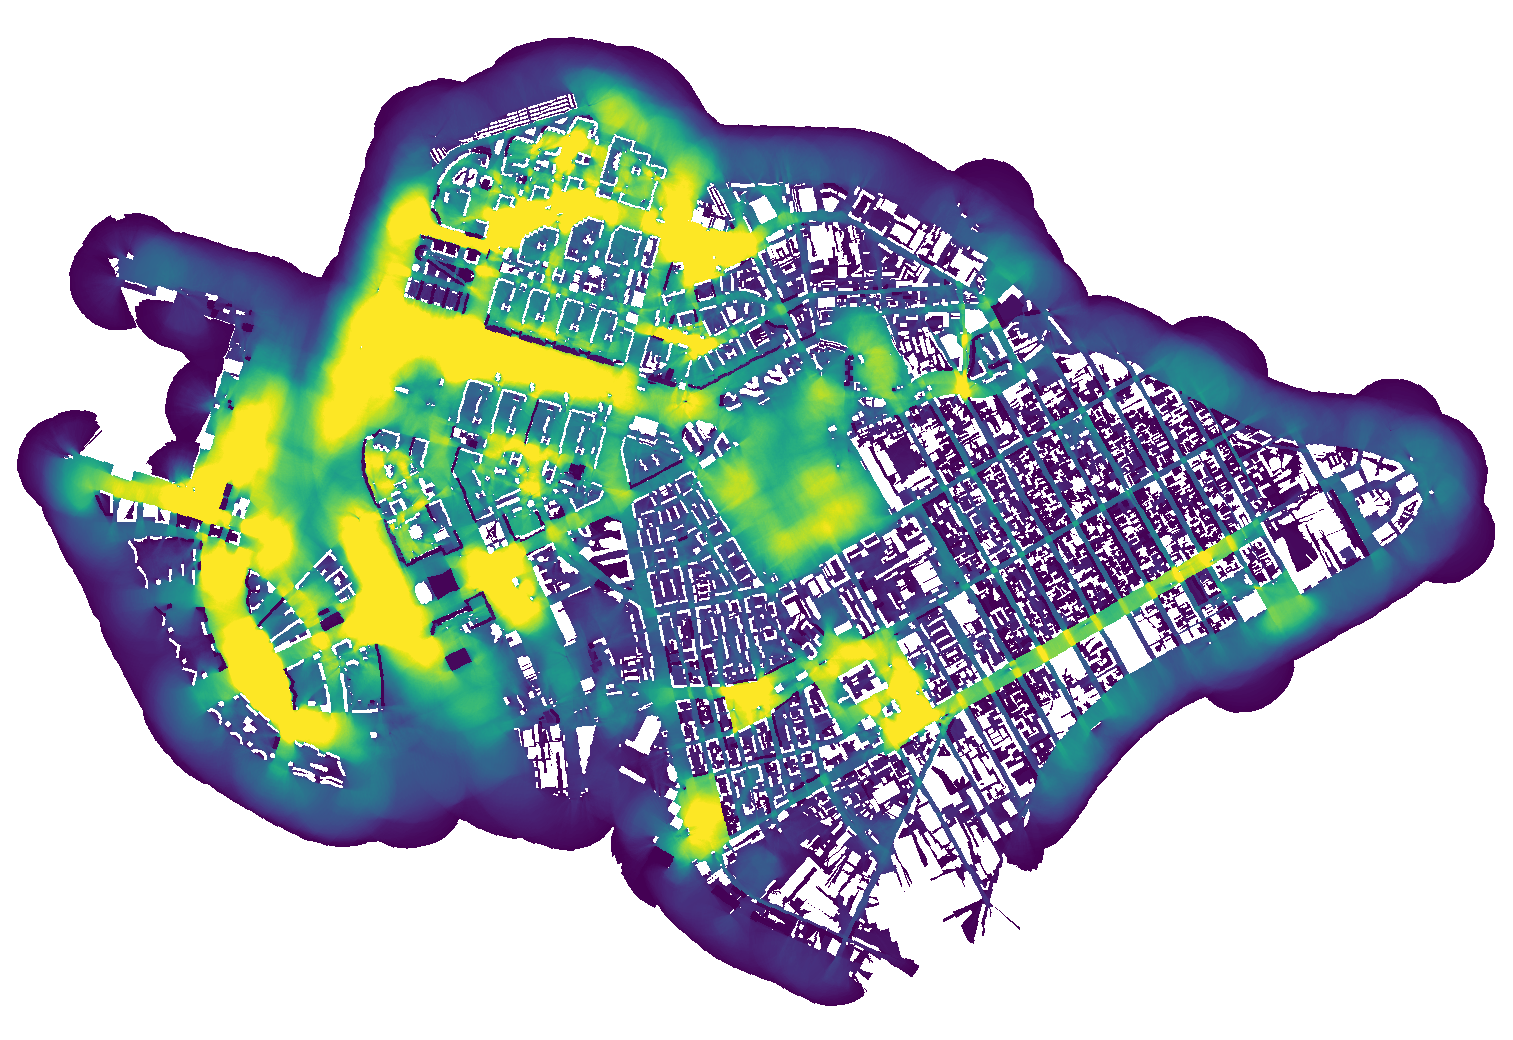

In [12]:
seen.explore(cmap="viridis", vmin=1, vmax=300, name="observers that see the cell")